## 1. Bibliotecas

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

##2. Carregar a base de Dados Fashion MNIST

In [ ]:
from tensorflow.keras.datasets import fashion_mnist

(X_train, y_train), (X_test, y_test)= fashion_mnist.load_data()

**(Opcional)** Linha de código para usar o .csv do kaggle.

In [ ]:
#df= pd.read_csv("fashion-mnist_test.csv")
#y_train= df["label"].to_numpy()
#X_train= df.drop(columns="label").to_numpy().reshape(-1, 28, 28).astype("uint8")

**(Observação)** Foi utilizado apenas a amostragem do X_train para a plotagem dos gráficos

In [ ]:
class_names= {
    0: "T-shirt/top",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle boot"
}

print(f"Formato de X_train: ", X_train.shape)
print(f"Formato de y_train: ", y_train.shape)
print(f"Formato de X_test: ", X_test.shape)
print(f"Formato de y_test: ", y_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Formato de X_train:  (60000, 28, 28)
Formato de y_train:  (60000,)
Formato de X_test:  (10000, 28, 28)
Formato de y_test:  (10000,)


## 3. Estrutura geral

In [ ]:
#Monta o DataFrame de treino
df_train= pd.DataFrame(
    X_train.reshape(len(X_train), -1),
    columns=[f"pixel{i+1}" for i in range(784)]
)
df_train.insert(0, "label", y_train)

df_train.info(verbose=True, show_counts=True)
df_train.describe()

print(f"Imagens: {X_train.shape[0]} | Tamanho: {X_train.shape[1]}x{X_train.shape[2]} | dtype: {X_train.dtype}")
print(f"Intervalo de pixels: {X_train.min()} a {X_train.max()}")

#Valores nulos e duplicatas (usando uma versão achatada)
flat= pd.DataFrame(X_train.reshape(len(X_train), -1))
print("Valores nulos:", flat.isna().sum().sum())
print("Imagens duplicadas:", flat.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60000 entries, 0 to 59999
Data columns (total 785 columns):
 #    Column    Non-Null Count  Dtype
---   ------    --------------  -----
 0    label     60000 non-null  uint8
 1    pixel1    60000 non-null  uint8
 2    pixel2    60000 non-null  uint8
 3    pixel3    60000 non-null  uint8
 4    pixel4    60000 non-null  uint8
 5    pixel5    60000 non-null  uint8
 6    pixel6    60000 non-null  uint8
 7    pixel7    60000 non-null  uint8
 8    pixel8    60000 non-null  uint8
 9    pixel9    60000 non-null  uint8
 10   pixel10   60000 non-null  uint8
 11   pixel11   60000 non-null  uint8
 12   pixel12   60000 non-null  uint8
 13   pixel13   60000 non-null  uint8
 14   pixel14   60000 non-null  uint8
 15   pixel15   60000 non-null  uint8
 16   pixel16   60000 non-null  uint8
 17   pixel17   60000 non-null  uint8
 18   pixel18   60000 non-null  uint8
 19   pixel19   60000 non-null  uint8
 20   pixel20   60000 non-null  uint8
 21   pixel21   

## 4. Distribuição das classes

,n_imagens
T-shirt/top,6000
Trouser,6000
Pullover,6000
Dress,6000
Coat,6000
Sandal,6000
Shirt,6000
Sneaker,6000
Bag,6000
Ankle boot,6000


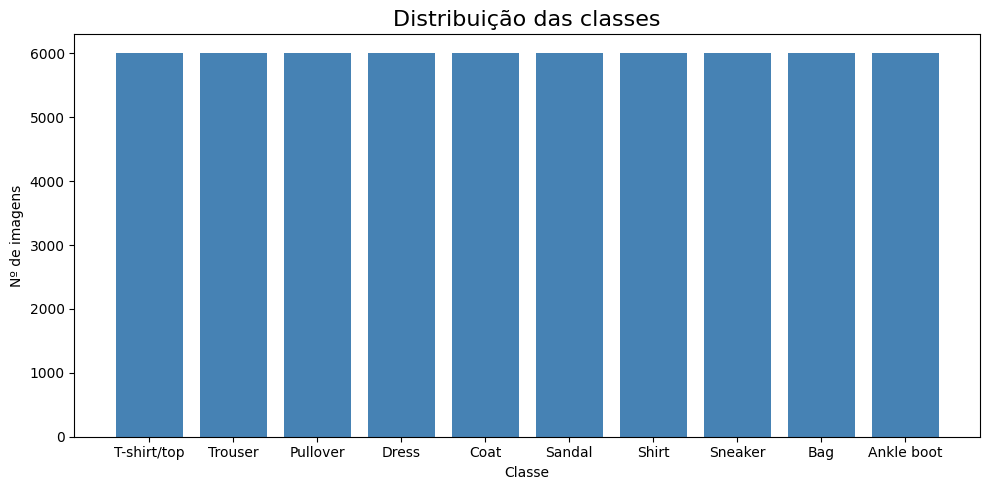

In [ ]:
contagem= pd.Series(y_train).value_counts().sort_index()
contagem.index= [class_names[i] for i in contagem.index]
display(contagem.to_frame("n_imagens"))

plt.figure(figsize=(10, 5))
plt.bar(contagem.index, contagem.values, color= 'steelblue')
plt.title("Distribuição das classes", fontsize= 16)
plt.ylabel("Nº de imagens")
plt.xlabel("Classe")
plt.tight_layout()
plt.show()

## 5. Brilho médio por classe

,brilho_medio
Sandal,34.87
Sneaker,42.76
Trouser,56.84
Dress,66.02
Ankle boot,76.81
T-shirt/top,83.03
Shirt,84.61
Bag,90.16
Pullover,96.06
Coat,98.26


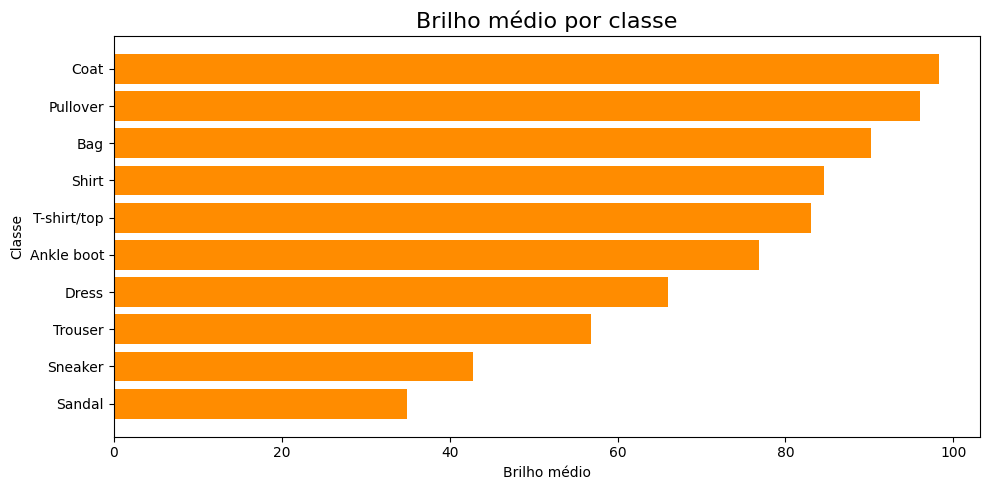

In [ ]:
brilho= pd.Series(X_train.reshape(len(X_train), -1).mean(axis=1)).groupby(y_train).mean()
brilho.index= [class_names[i] for i in brilho.index]
brilho= brilho.sort_values()
display(brilho.round(2).to_frame("brilho_medio"))

plt.figure(figsize=(10, 5))
plt.barh(brilho.index, brilho.values, color= 'darkorange')
plt.title("Brilho médio por classe", fontsize=16)
plt.ylabel("Classe")
plt.xlabel("Brilho médio")
plt.tight_layout()
plt.show()

## 6. Um exemplo de cada classe

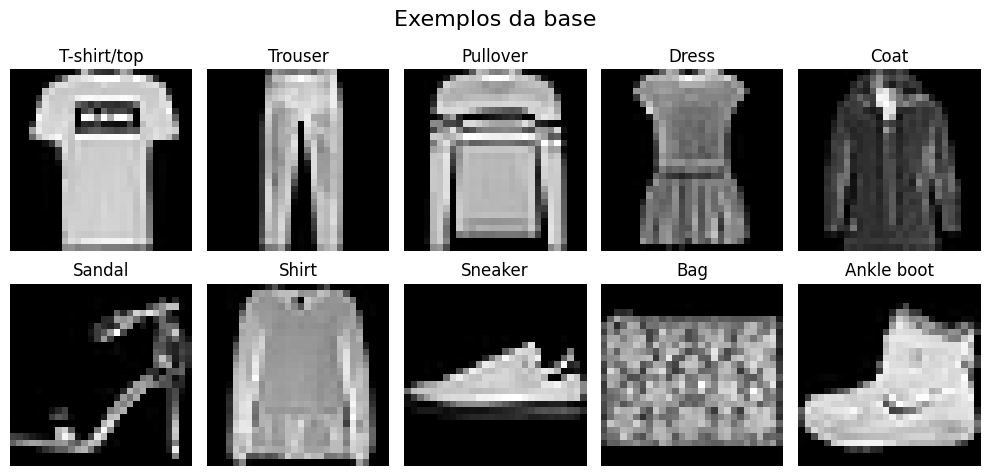

In [ ]:
plt.figure(figsize=(10, 5))
for i in range(10):
    idx= np.where(y_train== i)[0][0]
    plt.subplot(2, 5, i+1)
    plt.imshow(X_train[idx], cmap= 'gray')
    plt.title(class_names[i])
    plt.axis('off')
plt.suptitle("Exemplos da base", fontsize= 16)
plt.tight_layout()
plt.show()

## 7. Imagem média de cada classe

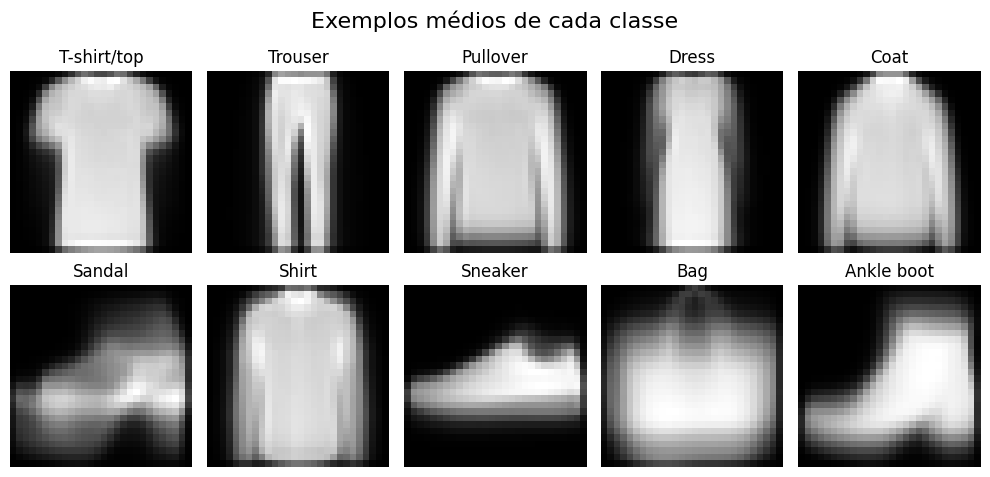

In [ ]:
plt.figure(figsize=(10, 5))
for i in range(10):
    plt.subplot(2, 5, i+1)
    plt.imshow(X_train[y_train== i].mean(axis=0), cmap= 'gray')
    plt.title(class_names[i])
    plt.axis('off')
plt.suptitle("Exemplos médios de cada classe", fontsize= 16)
plt.tight_layout()
plt.show()